<a href="https://colab.research.google.com/github/uditjaisw-cmyk/World-Trade-Network-Analysis/blob/main/Copy_of_Welcome_To_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

# Search for the BACI zip in your Drive
for root, dirs, files in os.walk('/content/drive/MyDrive'):
    for f in files:
        if 'BACI' in f and f.endswith('.zip'):
            full_path = os.path.join(root, f)
            print(full_path)

/content/drive/MyDrive/BACI_HS92_V202601.zip


In [ ]:
import zipfile, os

zip_path = "/content/drive/MyDrive/BACI_HS92_V202601.zip"  # ← your path here
extract_to = "/content/baci_data"

os.makedirs(extract_to, exist_ok=True)

print("Unzipping... this will take 3-5 minutes")
with zipfile.ZipFile(zip_path, 'r') as z:
    z.extractall(extract_to)

# Check what files were extracted
files = sorted(os.listdir(extract_to))
print(f"\nExtracted {len(files)} files:")
for f in files[:5]:
    print(" ", f)
print("  ...")
for f in files[-3:]:
    print(" ", f)

Unzipping... this will take 3-5 minutes

Extracted 33 files:
  BACI_HS92_Y1995_V202601.csv
  BACI_HS92_Y1996_V202601.csv
  BACI_HS92_Y1997_V202601.csv
  BACI_HS92_Y1998_V202601.csv
  BACI_HS92_Y1999_V202601.csv
  ...
  Readme.txt
  country_codes_V202601.csv
  product_codes_HS92_V202601.csv


In [ ]:
!pip install networkx matplotlib pandas numpy scipy -q
print("All packages ready!")

All packages ready!


  WTN Visualisation  |  2024  |  48-country panel

  Loading BACI 2024 …
  2,240 bilateral flows | 48 exporters | 48 importers

  [1/5] Fig 2 — Geographical layout …
  ✓  Saved → /content/drive/MyDrive/WTN_figures/fig2_geo_2024.png


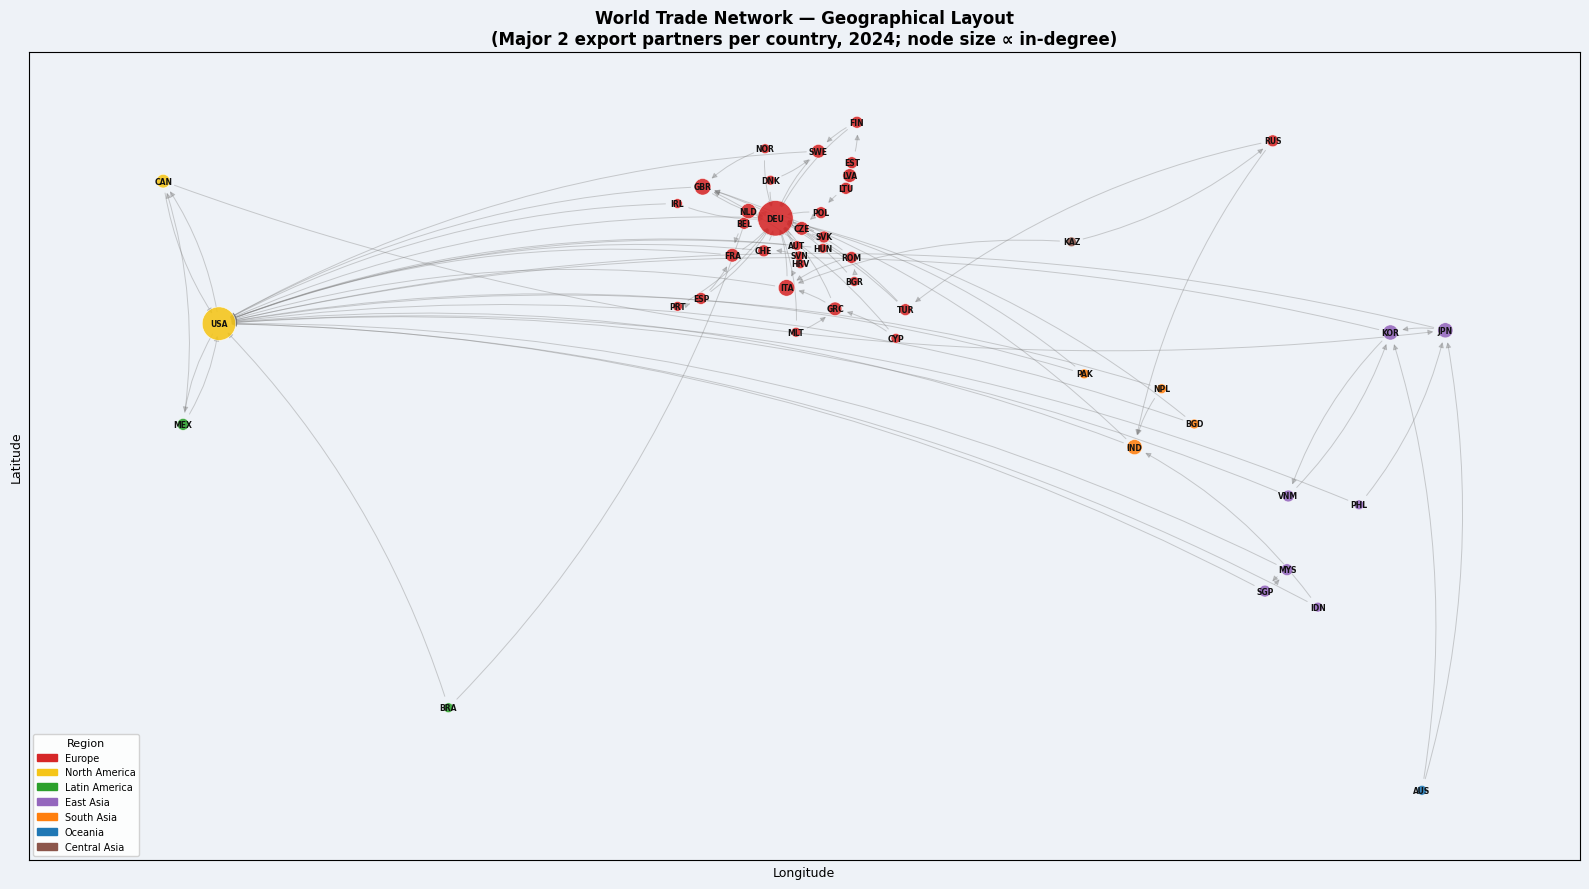


  [2/5] Fig 3 — Kamada-Kawai force layout …
  ✓  Saved → /content/drive/MyDrive/WTN_figures/fig3_kk_2024.png


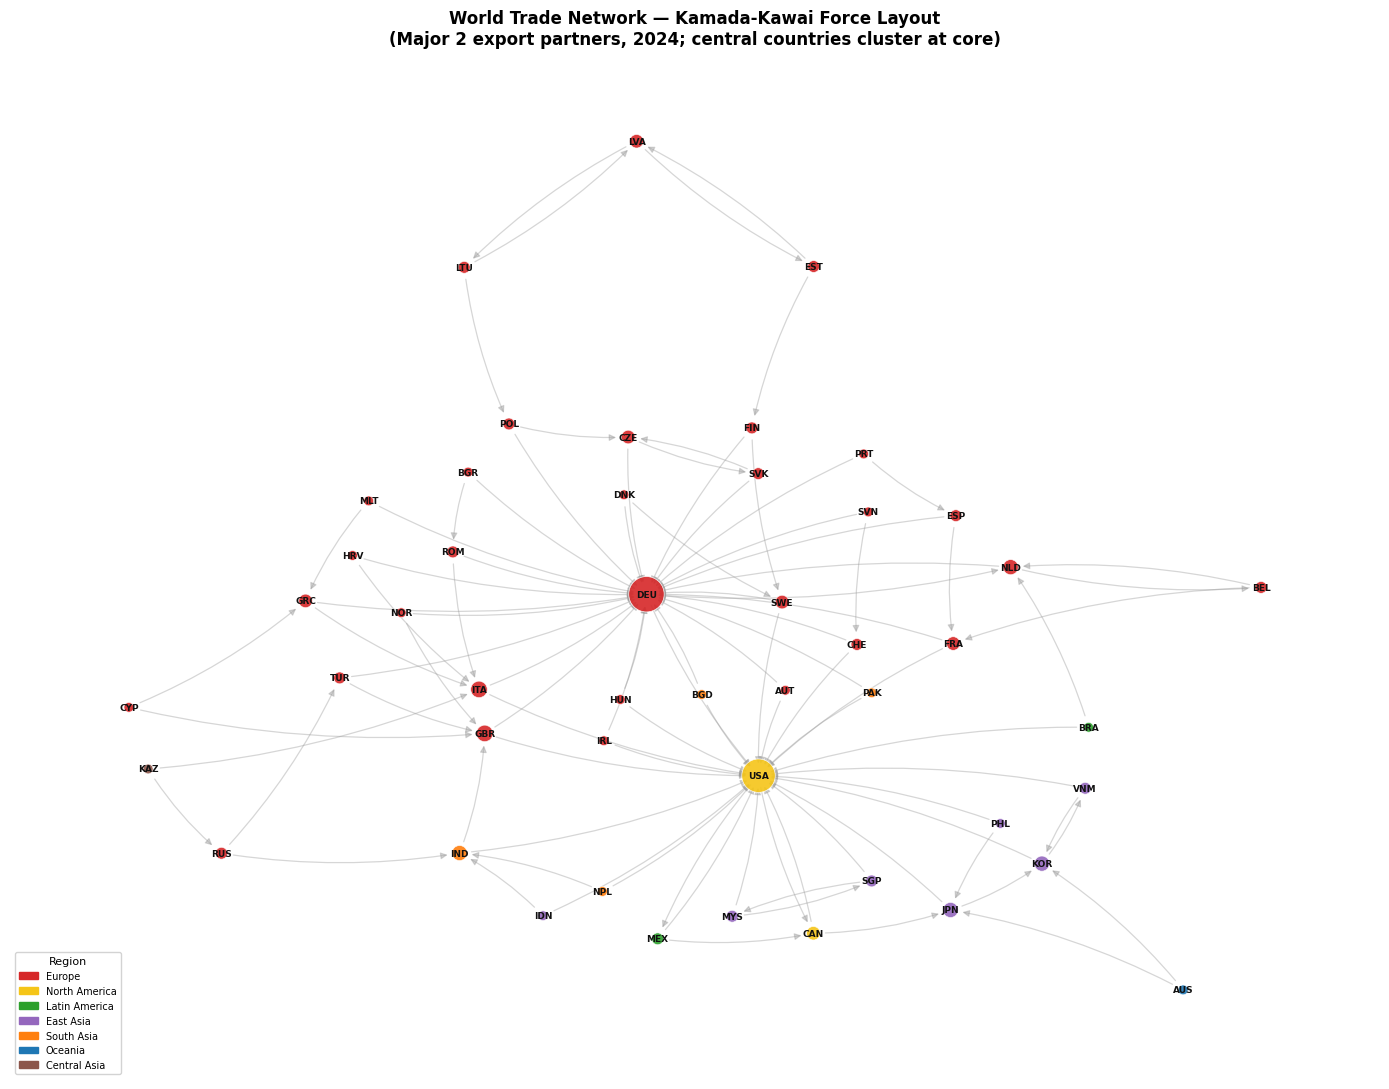


  [3/5] Fig 6 — Trade-threshold panels (25/50/75/90 %) …
  ✓  Saved → /content/drive/MyDrive/WTN_figures/fig6_thresholds_2024.png


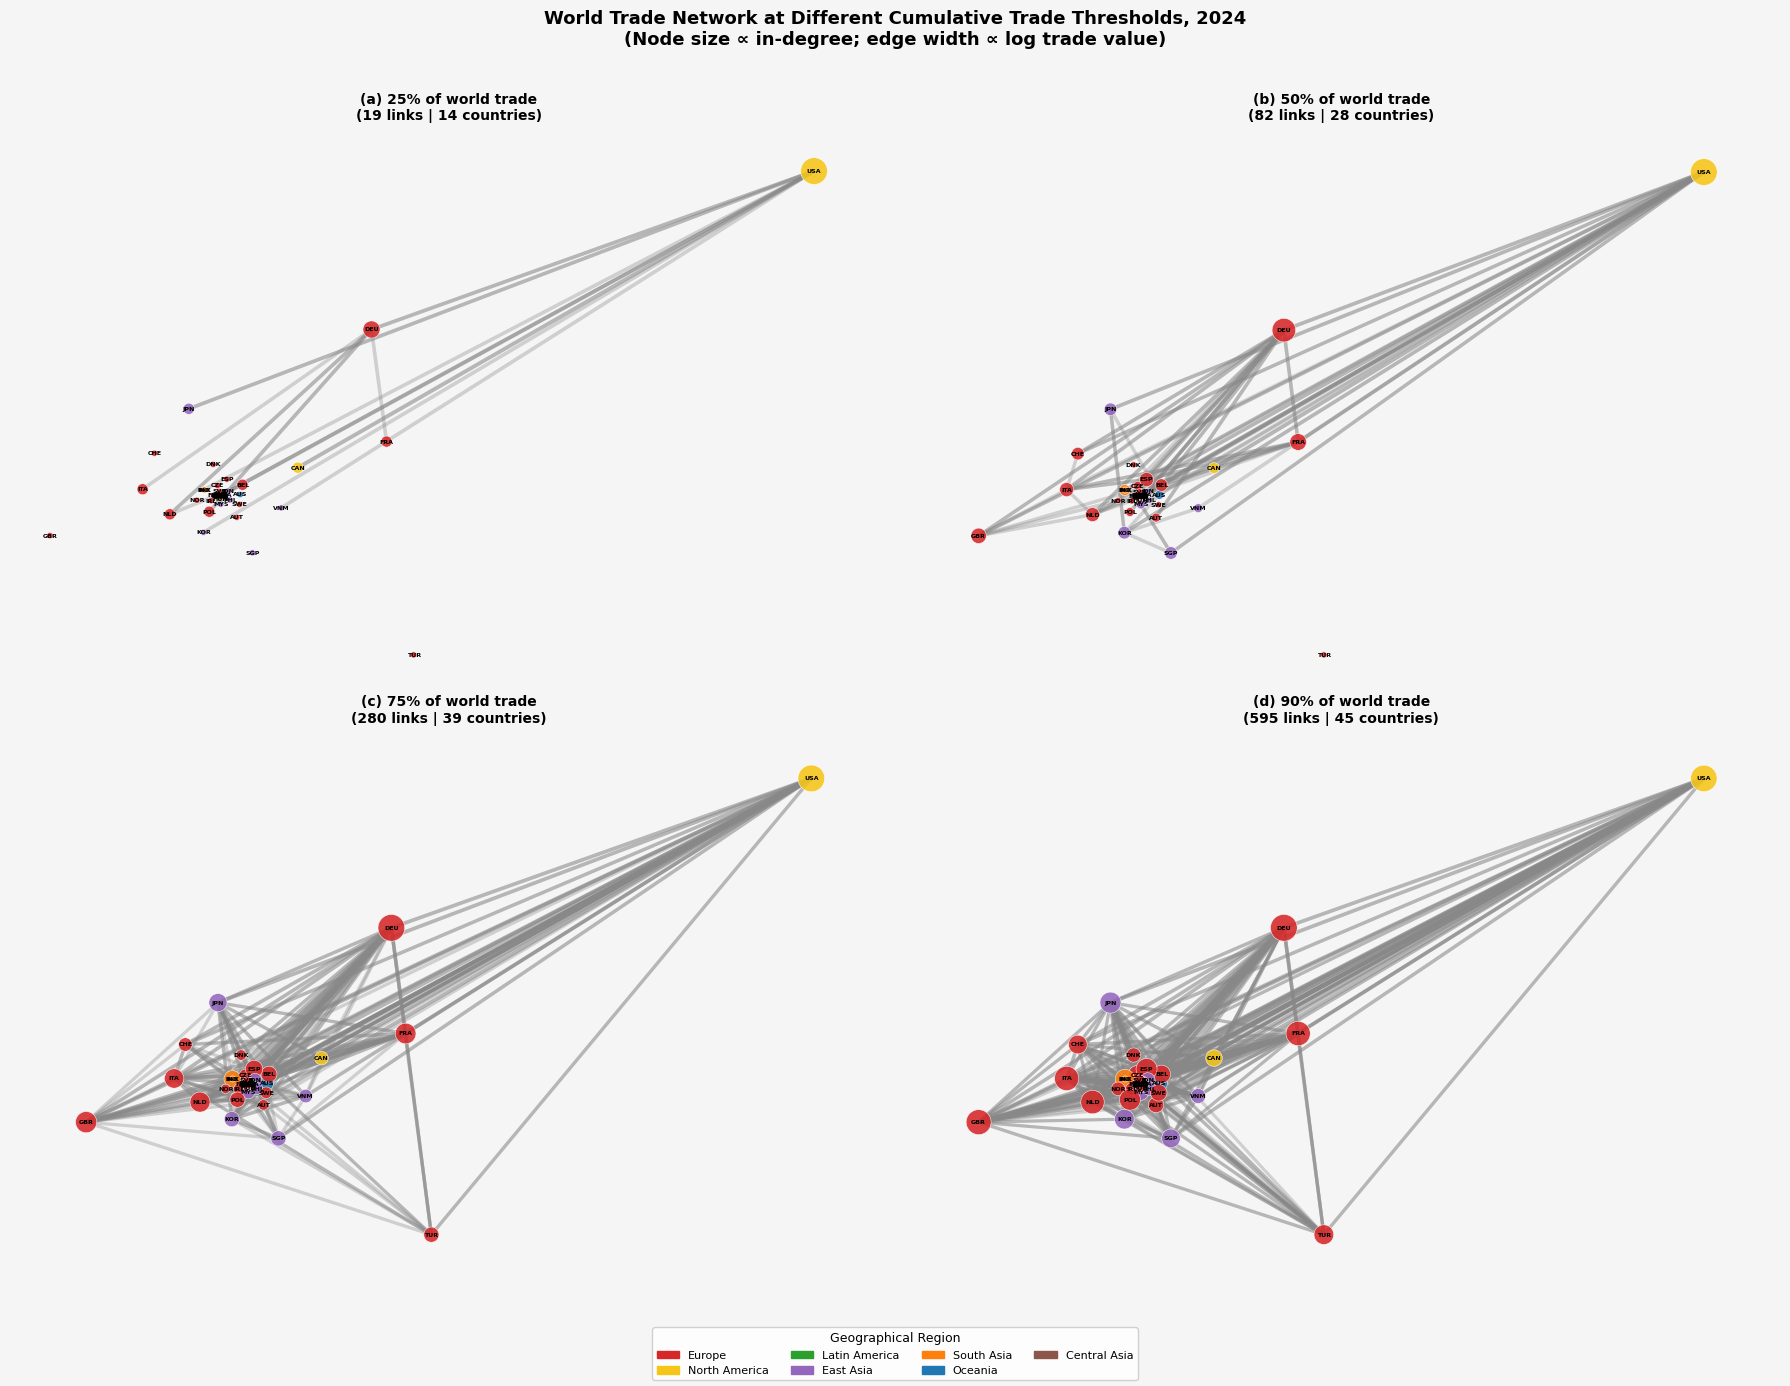


  [4/5] Fig 7 — Europe zoom …
  ✓  Saved → /content/drive/MyDrive/WTN_figures/fig7_europe_2024.png


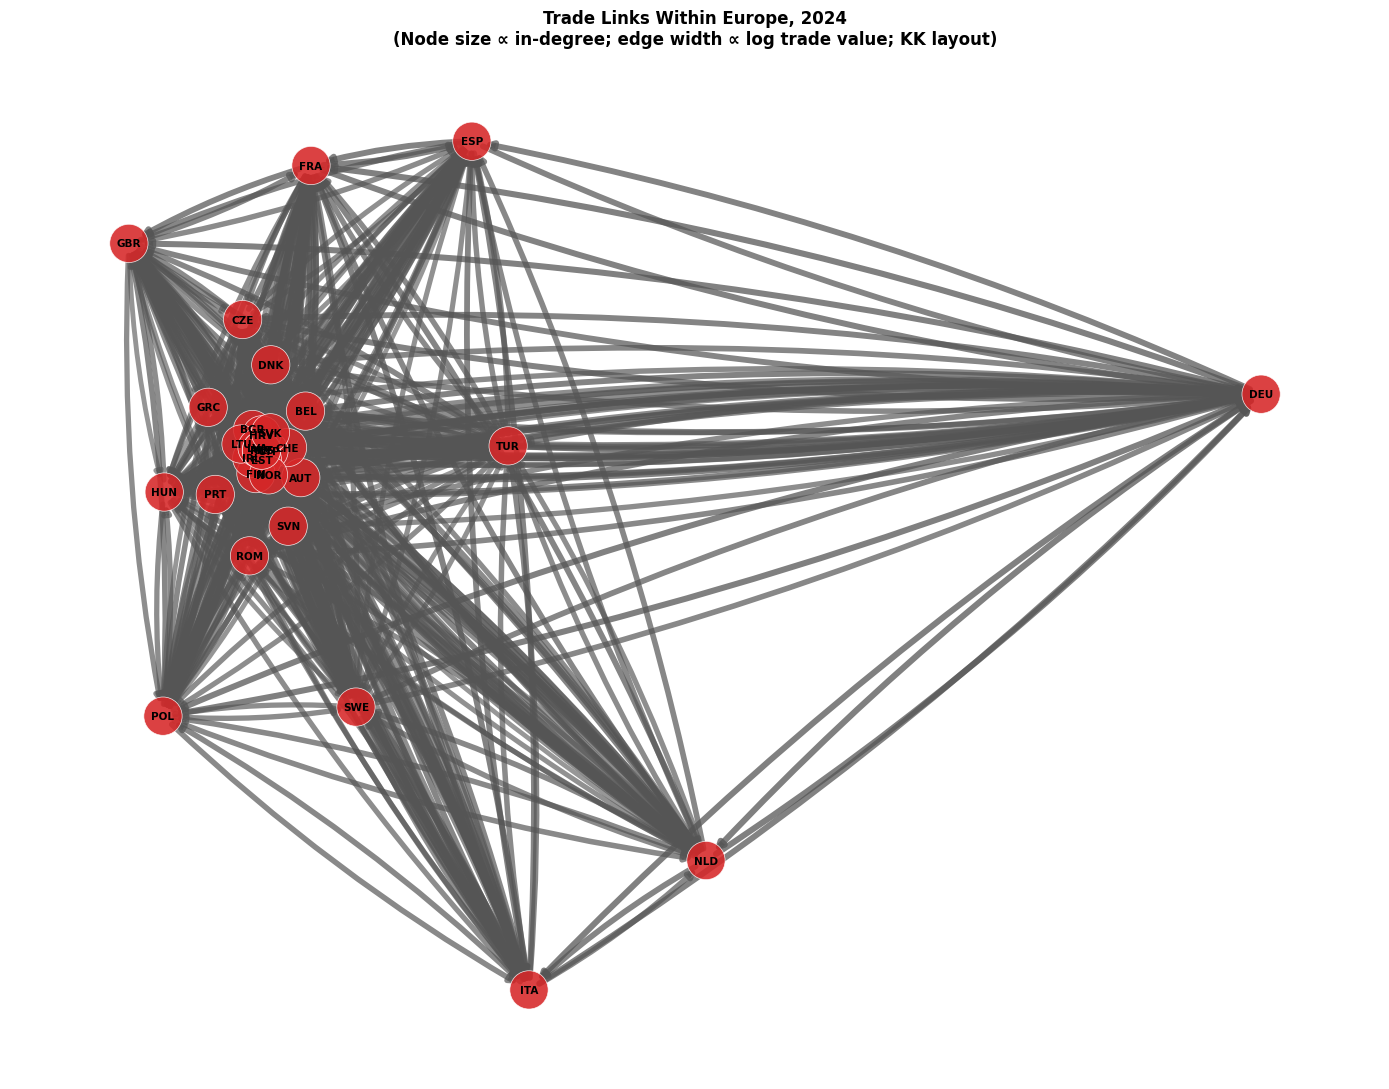


  [5/5] Fig 8 — Regional aggregation …
  ✓  Saved → /content/drive/MyDrive/WTN_figures/fig8_regional_2024.png


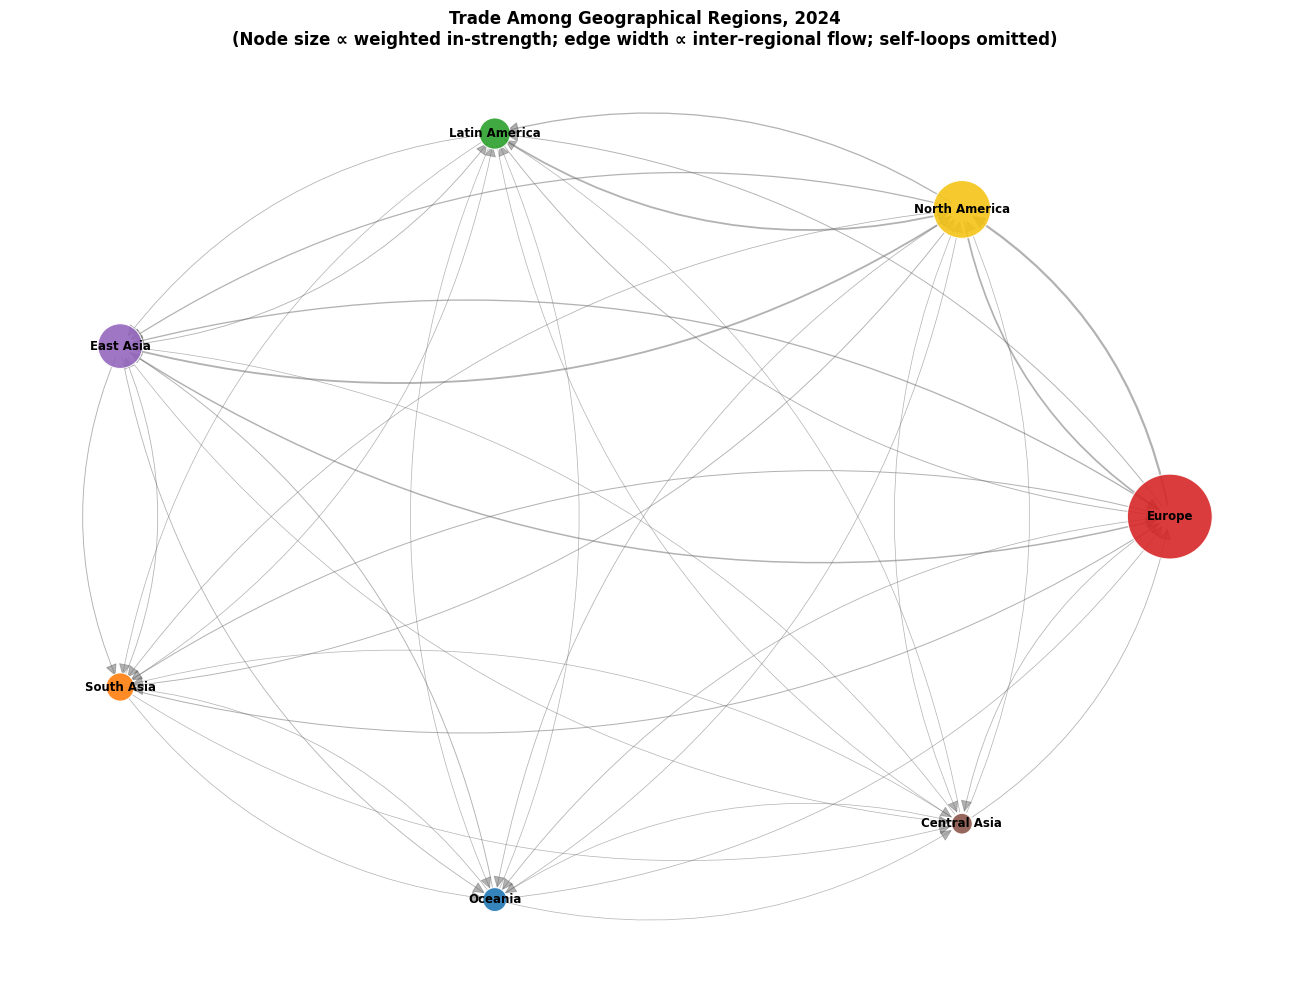


  All figures → /content/drive/MyDrive/WTN_figures


In [ ]:
"""
World Trade Network Visualisation — Python / NetworkX
======================================================
Replicates Appendix 7.3 of De Benedictis et al. (2013),
CEPII Working Paper No. 2013-24, using Python instead of Pajek.

Produces 5 figure types (≈ Figs 2, 3, 6, 7, 8 of the paper)
+ a bonus centrality-heatmap, all saved as high-resolution PNG.

PANEL : 48 countries  |  YEARS : 2005-2024  (one year per run)

REQUIREMENTS (run once):
    pip install networkx matplotlib pandas numpy scipy

HOW TO RUN:
    1. Set BACI_DIR, OUTPUT_DIR, YEAR below.
    2. python wtn_visualisation.py
       — or paste the whole file into a single Colab cell.

STEPS OVERVIEW
--------------
Step 1  Country metadata  – lat/lon, region, colour for each of 48 ISO-3 codes
Step 2  Load BACI         – aggregate product-level flows to bilateral country pairs
Step 3  Build graphs      – (a) top-2 export partner binary graph
                            (b) full weighted directed graph
                            (c) threshold sub-graphs (25 / 50 / 75 / 90 %)
                            (d) regional aggregation graph
Step 4  Layouts           – geographic (lon, lat) or Kamada-Kawai spring
Step 5  Draw figures
        Fig 2  Geo layout   : countries at real coordinates, top-2 export arcs
        Fig 3  KK layout    : force-directed, same top-2 arcs, structural position
        Fig 6  Thresholds   : 2×2 panel showing trade at 25/50/75/90 % of world total
        Fig 7  Europe zoom  : intra-European links only, KK layout
        Fig 8  Regions      : flows aggregated to 7 macro-regions, circular layout
        Bonus  Heatmap      : centrality measure × country × year (reads saved CSV)
"""

import os
import glob
import warnings

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

warnings.filterwarnings("ignore")

# ─────────────────────────────────────────────────────────────────────────────
# CONFIG  ← edit these three lines
# ─────────────────────────────────────────────────────────────────────────────
BACI_DIR   = "/content/baci_data"           # folder with BACI_HS92_Y{year}_V*.csv
OUTPUT_DIR = "/content/drive/MyDrive/WTN_figures"           # where to write PNG files
YEAR       = 2024                           # reference year for visualisation

os.makedirs(OUTPUT_DIR, exist_ok=True)

# ─────────────────────────────────────────────────────────────────────────────
# STEP 1 — COUNTRY METADATA
# columns : (cid, numeric_iso, iso3, name, lat, lon, region, hex_colour)
# ─────────────────────────────────────────────────────────────────────────────
COUNTRY_META = [
    ( 10,  36, "AUS", "Australia",          -25.27,  133.78, "Oceania",        "#1f77b4"),
    ( 11,  40, "AUT", "Austria",             47.52,   14.55, "Europe",         "#d62728"),
    ( 16,  50, "BGD", "Bangladesh",          23.68,   90.35, "South Asia",     "#ff7f0e"),
    ( 17, 100, "BGR", "Bulgaria",            42.73,   25.49, "Europe",         "#d62728"),
    ( 21,  56, "BEL", "Belgium",             50.50,    4.47, "Europe",         "#d62728"),
    ( 25,  76, "BRA", "Brazil",             -14.24,  -51.93, "Latin America",  "#2ca02c"),
    ( 30, 124, "CAN", "Canada",              56.13, -106.35, "North America",  "#f5c518"),
    ( 31, 757, "CHE", "Switzerland",         46.82,    8.23, "Europe",         "#d62728"),
    ( 41, 196, "CYP", "Cyprus",              35.13,   33.43, "Europe",         "#d62728"),
    ( 42, 203, "CZE", "Czech Republic",      49.82,   15.47, "Europe",         "#d62728"),
    ( 43, 276, "DEU", "Germany",             51.17,   10.45, "Europe",         "#d62728"),
    ( 45, 208, "DNK", "Denmark",             56.26,    9.50, "Europe",         "#d62728"),
    ( 50, 724, "ESP", "Spain",               40.46,   -3.75, "Europe",         "#d62728"),
    ( 51, 233, "EST", "Estonia",             58.60,   25.01, "Europe",         "#d62728"),
    ( 53, 246, "FIN", "Finland",             64.00,   26.00, "Europe",         "#d62728"),
    ( 55, 251, "FRA", "France",              46.23,    2.21, "Europe",         "#d62728"),
    ( 58, 826, "GBR", "United Kingdom",      55.38,   -3.44, "Europe",         "#d62728"),
    ( 65, 300, "GRC", "Greece",              39.07,   21.82, "Europe",         "#d62728"),
    ( 70, 191, "HRV", "Croatia",             45.10,   15.20, "Europe",         "#d62728"),
    ( 72, 348, "HUN", "Hungary",             47.16,   19.50, "Europe",         "#d62728"),
    ( 73, 360, "IDN", "Indonesia",           -0.79,  113.92, "East Asia",      "#9467bd"),
    ( 74, 699, "IND", "India",               20.59,   78.96, "South Asia",     "#ff7f0e"),
    ( 75, 372, "IRL", "Ireland",             53.14,   -8.24, "Europe",         "#d62728"),
    ( 80, 380, "ITA", "Italy",               41.87,   12.57, "Europe",         "#d62728"),
    ( 83, 392, "JPN", "Japan",               36.20,  138.25, "East Asia",      "#9467bd"),
    ( 84, 398, "KAZ", "Kazakhstan",          48.02,   66.92, "Central Asia",   "#8c564b"),
    ( 89, 410, "KOR", "South Korea",         35.91,  127.77, "East Asia",      "#9467bd"),
    ( 97, 440, "LTU", "Lithuania",           55.17,   23.88, "Europe",         "#d62728"),
    ( 98, 428, "LVA", "Latvia",              56.88,   24.60, "Europe",         "#d62728"),
    (104, 484, "MEX", "Mexico",              23.63, -102.55, "Latin America",  "#2ca02c"),
    (108, 470, "MLT", "Malta",               35.94,   14.38, "Europe",         "#d62728"),
    (115, 458, "MYS", "Malaysia",             4.21,  108.04, "East Asia",      "#9467bd"),
    (120, 528, "NLD", "Netherlands",         52.13,    5.29, "Europe",         "#d62728"),
    (121, 579, "NOR", "Norway",              60.47,    8.47, "Europe",         "#d62728"),
    (122, 524, "NPL", "Nepal",               28.39,   84.12, "South Asia",     "#ff7f0e"),
    (125, 586, "PAK", "Pakistan",            30.38,   69.35, "South Asia",     "#ff7f0e"),
    (128, 608, "PHL", "Philippines",         12.88,  121.77, "East Asia",      "#9467bd"),
    (130, 616, "POL", "Poland",              51.92,   19.15, "Europe",         "#d62728"),
    (132, 620, "PRT", "Portugal",            39.40,   -8.22, "Europe",         "#d62728"),
    (135, 642, "ROM", "Romania",             45.94,   24.97, "Europe",         "#d62728"),
    (136, 643, "RUS", "Russian Fed.",        61.52,  105.32, "Europe",         "#d62728"),
    (141, 702, "SGP", "Singapore",            1.35,  103.82, "East Asia",      "#9467bd"),
    (147, 703, "SVK", "Slovak Republic",     48.67,   19.70, "Europe",         "#d62728"),
    (148, 705, "SVN", "Slovenia",            46.15,   14.99, "Europe",         "#d62728"),
    (149, 752, "SWE", "Sweden",              60.13,   18.64, "Europe",         "#d62728"),
    (159, 792, "TUR", "Turkey",              38.96,   35.24, "Europe",         "#d62728"),
    (165, 842, "USA", "United States",       37.09,  -95.71, "North America",  "#f5c518"),
    (170, 704, "VNM", "Vietnam",             14.06,  108.28, "East Asia",      "#9467bd"),
]

# Convenience lookups
ISO3_META   = {row[2]: row for row in COUNTRY_META}          # iso3 → full row
NUM_TO_ISO  = {row[1]: row[2] for row in COUNTRY_META}       # numeric → iso3
PANEL_ISO3  = [row[2] for row in COUNTRY_META]

REGION_COLORS = {
    "Europe":        "#d62728",
    "North America": "#f5c518",
    "Latin America": "#2ca02c",
    "East Asia":     "#9467bd",
    "South Asia":    "#ff7f0e",
    "Oceania":       "#1f77b4",
    "Central Asia":  "#8c564b",
}


# ─────────────────────────────────────────────────────────────────────────────
# STEP 2 — LOAD BACI  (identical logic to the centrality script)
# ─────────────────────────────────────────────────────────────────────────────
def load_bilateral(year: int) -> pd.DataFrame:
    """
    Read BACI CSV for `year`, filter to the 48-country panel,
    aggregate product-level flows to bilateral totals.
    Returns DataFrame with columns [exp, imp, val].
    """
    pattern = os.path.join(BACI_DIR, f"BACI_HS92_Y{year}_V*.csv")
    files   = glob.glob(pattern)
    if not files:
        raise FileNotFoundError(f"No BACI file for {year} — pattern: {pattern}")

    df = pd.read_csv(files[0], dtype={"k": str, "i": int, "j": int, "v": float})
    df["exp"] = df["i"].map(lambda x: NUM_TO_ISO.get(x))
    df["imp"] = df["j"].map(lambda x: NUM_TO_ISO.get(x))
    df = df.dropna(subset=["exp", "imp"])
    df = df[df["exp"] != df["imp"]]

    bil = (df.groupby(["exp", "imp"])["v"]
             .sum().reset_index()
             .rename(columns={"v": "val"}))
    print(f"  {len(bil):,} bilateral flows | "
          f"{bil['exp'].nunique()} exporters | {bil['imp'].nunique()} importers")
    return bil


# ─────────────────────────────────────────────────────────────────────────────
# STEP 3 — BUILD GRAPHS
# ─────────────────────────────────────────────────────────────────────────────
def build_full_graph(bilateral: pd.DataFrame) -> nx.DiGraph:
    """Full weighted directed graph (all bilateral flows, 48 nodes)."""
    G = nx.DiGraph()
    G.add_nodes_from(PANEL_ISO3)
    for _, r in bilateral.iterrows():
        if r["exp"] in ISO3_META and r["imp"] in ISO3_META:
            G.add_edge(r["exp"], r["imp"], weight=float(r["val"]))
    return G


def build_top_k_graph(bilateral: pd.DataFrame, k: int = 2) -> nx.DiGraph:
    """
    Binary directed graph keeping only each country's top-k export destinations.
    Replicates the data-compression used for Figs 2 & 3 in the paper.
    """
    G = nx.DiGraph()
    G.add_nodes_from(PANEL_ISO3)
    for exp, grp in bilateral.groupby("exp"):
        for _, r in grp.nlargest(k, "val").iterrows():
            G.add_edge(r["exp"], r["imp"], weight=1.0)
    return G


def build_threshold_graph(bilateral: pd.DataFrame,
                           threshold: float) -> nx.DiGraph:
    """
    Keep the strongest links that cumulatively account for
    `threshold` share of total world trade.
    """
    bil_s = bilateral.sort_values("val", ascending=False).copy()
    bil_s["cumshare"] = bil_s["val"].cumsum() / bil_s["val"].sum()
    subset = bil_s[bil_s["cumshare"].shift(1, fill_value=0.0) < threshold]

    G = nx.DiGraph()
    G.add_nodes_from(PANEL_ISO3)
    for _, r in subset.iterrows():
        if r["exp"] in ISO3_META and r["imp"] in ISO3_META:
            G.add_edge(r["exp"], r["imp"], weight=float(r["val"]))
    return G


# ─────────────────────────────────────────────────────────────────────────────
# STEP 4 — NODE-ATTRIBUTE HELPERS
# ─────────────────────────────────────────────────────────────────────────────
def geo_positions() -> dict:
    """Geographic layout: {iso3: (longitude, latitude)}."""
    return {row[2]: (row[5], row[4]) for row in COUNTRY_META}


def node_colours(nodes) -> list:
    return [ISO3_META[n][7] for n in nodes]


def size_by_indegree(G, nodes, base=50, scale=600) -> list:
    max_d = max(G.in_degree(n) for n in nodes) or 1
    return [base + scale * G.in_degree(n) / max_d for n in nodes]


def size_by_outdegree(G, nodes, base=50, scale=600) -> list:
    max_d = max(G.out_degree(n) for n in nodes) or 1
    return [base + scale * G.out_degree(n) / max_d for n in nodes]


def _legend_handles():
    return [mpatches.Patch(color=c, label=r)
            for r, c in REGION_COLORS.items()]


def _save(fig, fname: str):
    path = os.path.join(OUTPUT_DIR, fname)
    fig.savefig(path, dpi=180, bbox_inches="tight")
    print(f"  ✓  Saved → {path}")


# ─────────────────────────────────────────────────────────────────────────────
# STEP 5a — FIGURE 2  Geographical layout
# ─────────────────────────────────────────────────────────────────────────────
def fig2_geographical(bilateral: pd.DataFrame, year: int):
    """
    Countries are pinned to their real (lon, lat) coordinates.
    Arcs show each country's top-2 export destinations.
    Node size ∝ in-degree (number of countries pointing to it).

    Paper analogue: Figure 2
    """
    G    = build_top_k_graph(bilateral, k=2)
    pos  = geo_positions()
    nds  = list(G.nodes())
    szs  = size_by_indegree(G, nds)
    cols = node_colours(nds)

    fig, ax = plt.subplots(figsize=(16, 9))
    ax.set_facecolor("#eef2f7")
    fig.patch.set_facecolor("#eef2f7")

    # ── edges ──
    nx.draw_networkx_edges(
        G, pos, ax=ax,
        edge_color="#777777", alpha=0.35,
        arrows=True, arrowsize=8, width=0.7,
        connectionstyle="arc3,rad=0.12",
    )
    # ── nodes ──
    nx.draw_networkx_nodes(G, pos, ax=ax, node_size=szs,
                           node_color=cols, alpha=0.88, linewidths=0.4,
                           edgecolors="white")
    # ── labels ──
    nx.draw_networkx_labels(G, pos, ax=ax, font_size=5.5,
                            font_weight="bold", font_color="#111111")

    ax.legend(handles=_legend_handles(), loc="lower left",
              fontsize=7, title="Region", title_fontsize=8,
              framealpha=0.85)
    ax.set_title(
        f"World Trade Network — Geographical Layout\n"
        f"(Major 2 export partners per country, {year}; "
        f"node size ∝ in-degree)",
        fontsize=12, fontweight="bold",
    )
    ax.set_xlabel("Longitude", fontsize=9)
    ax.set_ylabel("Latitude",  fontsize=9)
    plt.tight_layout()
    _save(fig, f"fig2_geo_{year}.png")
    plt.show()


# ─────────────────────────────────────────────────────────────────────────────
# STEP 5b — FIGURE 3  Force-directed (Kamada-Kawai) layout
# ─────────────────────────────────────────────────────────────────────────────
def fig3_force_directed(bilateral: pd.DataFrame, year: int):
    """
    Same top-2 binary network as Fig 2 but the spring-minimisation
    (Kamada-Kawai) places structurally central countries at the core.
    This reveals multilateral interdependence invisible in the geo plot.

    Paper analogue: Figure 3
    """
    G    = build_top_k_graph(bilateral, k=2)
    Gu   = G.to_undirected()
    pos  = nx.kamada_kawai_layout(Gu, scale=2.5)
    nds  = list(G.nodes())
    szs  = size_by_indegree(G, nds)
    cols = node_colours(nds)

    fig, ax = plt.subplots(figsize=(14, 11))
    ax.set_facecolor("#fafafa")

    nx.draw_networkx_edges(
        G, pos, ax=ax,
        edge_color="#999999", alpha=0.40,
        arrows=True, arrowsize=10, width=0.9,
        connectionstyle="arc3,rad=0.08",
    )
    nx.draw_networkx_nodes(G, pos, ax=ax, node_size=szs,
                           node_color=cols, alpha=0.90,
                           linewidths=0.5, edgecolors="white")
    nx.draw_networkx_labels(G, pos, ax=ax, font_size=6.5,
                            font_weight="bold", font_color="#111111")

    ax.legend(handles=_legend_handles(), loc="lower left",
              fontsize=7, title="Region", title_fontsize=8, framealpha=0.85)
    ax.set_title(
        f"World Trade Network — Kamada-Kawai Force Layout\n"
        f"(Major 2 export partners, {year}; "
        f"central countries cluster at core)",
        fontsize=12, fontweight="bold",
    )
    ax.axis("off")
    plt.tight_layout()
    _save(fig, f"fig3_kk_{year}.png")
    plt.show()


# ─────────────────────────────────────────────────────────────────────────────
# STEP 5c — FIGURE 6  Trade thresholds (25 / 50 / 75 / 90 %)
# ─────────────────────────────────────────────────────────────────────────────
def fig6_trade_thresholds(bilateral: pd.DataFrame, year: int):
    """
    2×2 panel.  Each sub-figure adds more bilateral links until the
    displayed links account for 25, 50, 75 or 90 % of world trade.
    All panels share the same Kamada-Kawai positions (from the full graph).

    Paper analogue: Figure 6
    """
    # Shared layout from the full graph
    G_full = build_full_graph(bilateral)
    pos    = nx.kamada_kawai_layout(G_full.to_undirected(), scale=2.5)

    thresholds   = [0.25, 0.50, 0.75, 0.90]
    panel_titles = ["(a) 25% of world trade", "(b) 50% of world trade",
                    "(c) 75% of world trade", "(d) 90% of world trade"]

    fig, axes = plt.subplots(2, 2, figsize=(18, 14))
    fig.patch.set_facecolor("#f5f5f5")

    bil_sorted = bilateral.sort_values("val", ascending=False).copy()
    total      = bil_sorted["val"].sum()
    bil_sorted["cumshare"] = bil_sorted["val"].cumsum() / total

    for ax, thr, title in zip(axes.flatten(), thresholds, panel_titles):
        # select flows up to this threshold
        subset = bil_sorted[bil_sorted["cumshare"].shift(1, fill_value=0.0) < thr]

        G_sub = nx.DiGraph()
        G_sub.add_nodes_from(PANEL_ISO3)
        for _, r in subset.iterrows():
            if r["exp"] in ISO3_META and r["imp"] in ISO3_META:
                G_sub.add_edge(r["exp"], r["imp"], weight=float(r["val"]))

        nds  = PANEL_ISO3
        szs  = size_by_indegree(G_sub, nds, base=20, scale=350)
        cols = node_colours(nds)

        # edge grey-scale proportional to log-weight
        edges = list(G_sub.edges(data=True))
        if edges:
            lw_max = np.log1p(max(d["weight"] for _, _, d in edges))
            widths = [0.3 + 2.5 * np.log1p(d["weight"]) / lw_max
                      for _, _, d in edges]
        else:
            widths = []

        ax.set_facecolor("#fafafa")
        if edges:
            nx.draw_networkx_edges(G_sub, pos, ax=ax,
                                   edge_color="#888888",
                                   width=widths, alpha=0.35,
                                   arrows=False)
        nx.draw_networkx_nodes(G_sub, pos, ax=ax, node_size=szs,
                               node_color=cols, alpha=0.88,
                               linewidths=0.4, edgecolors="white")
        nx.draw_networkx_labels(G_sub, pos, ax=ax, font_size=4.5,
                                font_weight="bold")

        active = G_sub.number_of_edges()
        ax.set_title(f"{title}\n({active} links | "
                     f"{sum(1 for n in PANEL_ISO3 if G_sub.degree(n)>0)} countries)",
                     fontsize=10, fontweight="bold")
        ax.axis("off")

    fig.legend(handles=_legend_handles(), loc="lower center",
               ncol=4, fontsize=8, title="Geographical Region",
               title_fontsize=9, framealpha=0.9)
    fig.suptitle(
        f"World Trade Network at Different Cumulative Trade Thresholds, {year}\n"
        f"(Node size ∝ in-degree; edge width ∝ log trade value)",
        fontsize=13, fontweight="bold",
    )
    plt.tight_layout(rect=[0, 0.06, 1, 0.97])
    _save(fig, f"fig6_thresholds_{year}.png")
    plt.show()


# ─────────────────────────────────────────────────────────────────────────────
# STEP 5d — FIGURE 7  Zoom into European countries
# ─────────────────────────────────────────────────────────────────────────────
def fig7_europe_zoom(bilateral: pd.DataFrame, year: int):
    """
    Extract the intra-European sub-network and apply its own KK layout.
    Edge width encodes log trade volume.

    Paper analogue: Figure 7
    """
    eu = [row[2] for row in COUNTRY_META if row[6] == "Europe"]
    bil_eu = bilateral[
        bilateral["exp"].isin(eu) & bilateral["imp"].isin(eu)
    ]

    G_eu = nx.DiGraph()
    G_eu.add_nodes_from(eu)
    for _, r in bil_eu.iterrows():
        G_eu.add_edge(r["exp"], r["imp"], weight=float(r["val"]))

    pos  = nx.kamada_kawai_layout(G_eu.to_undirected(), scale=2.5)
    nds  = eu
    szs  = size_by_indegree(G_eu, nds, base=60, scale=700)

    edges = list(G_eu.edges(data=True))
    if edges:
        lw_max = np.log1p(max(d["weight"] for _, _, d in edges))
        widths = [0.4 + 4.0 * np.log1p(d["weight"]) / lw_max
                  for _, _, d in edges]
        alphas = [0.20 + 0.55 * np.log1p(d["weight"]) / lw_max
                  for _, _, d in edges]
    else:
        widths, alphas = [], []

    fig, ax = plt.subplots(figsize=(14, 11))
    ax.set_facecolor("#fafafa")

    for (u, v, d), w, a in zip(edges, widths, alphas):
        nx.draw_networkx_edges(G_eu, pos, ax=ax,
                               edgelist=[(u, v)],
                               edge_color="#555555",
                               width=w, alpha=a,
                               arrows=True, arrowsize=10,
                               connectionstyle="arc3,rad=0.06")

    nx.draw_networkx_nodes(G_eu, pos, ax=ax, node_size=szs,
                           node_color="#d62728", alpha=0.88,
                           linewidths=0.5, edgecolors="white")
    nx.draw_networkx_labels(G_eu, pos, ax=ax, font_size=7.5,
                            font_weight="bold")

    ax.set_title(
        f"Trade Links Within Europe, {year}\n"
        f"(Node size ∝ in-degree; edge width ∝ log trade value; "
        f"KK layout)",
        fontsize=12, fontweight="bold",
    )
    ax.axis("off")
    plt.tight_layout()
    _save(fig, f"fig7_europe_{year}.png")
    plt.show()


# ─────────────────────────────────────────────────────────────────────────────
# STEP 5e — FIGURE 8  Aggregated by geographical regions
# ─────────────────────────────────────────────────────────────────────────────
def fig8_regional(bilateral: pd.DataFrame, year: int):
    """
    Collapse countries to 7 macro-regions.  Each arc's weight is the
    sum of all bilateral flows between the two regions.
    Self-loops represent intra-regional trade.

    Paper analogue: Figure 8
    """
    iso_reg = {row[2]: row[6] for row in COUNTRY_META}
    bil = bilateral.copy()
    bil["exp_reg"] = bil["exp"].map(iso_reg)
    bil["imp_reg"] = bil["imp"].map(iso_reg)
    bil = bil.dropna(subset=["exp_reg", "imp_reg"])

    reg_trade = bil.groupby(["exp_reg", "imp_reg"])["val"].sum().reset_index()

    regions = list(REGION_COLORS.keys())
    G_reg   = nx.DiGraph()
    G_reg.add_nodes_from(regions)
    for _, r in reg_trade.iterrows():
        if r["exp_reg"] in G_reg and r["imp_reg"] in G_reg:
            if G_reg.has_edge(r["exp_reg"], r["imp_reg"]):
                G_reg[r["exp_reg"]][r["imp_reg"]]["weight"] += r["val"]
            else:
                G_reg.add_edge(r["exp_reg"], r["imp_reg"],
                               weight=float(r["val"]))

    # Circular layout for regions
    pos = nx.circular_layout(G_reg, scale=2.0)

    wmax   = max(d["weight"] for _, _, d in G_reg.edges(data=True))
    node_sz = [200 + 2800 * G_reg.in_degree(n, weight="weight") / wmax
               for n in regions]
    colours = [REGION_COLORS[n] for n in regions]

    edges  = [(u, v, d) for u, v, d in G_reg.edges(data=True) if u != v]
    widths = [0.5 + 7.0 * d["weight"] / wmax for _, _, d in edges]

    fig, ax = plt.subplots(figsize=(13, 10))
    ax.set_facecolor("#fafafa")

    nx.draw_networkx_edges(G_reg, pos, ax=ax,
                           edgelist=[(u, v) for u, v, _ in edges],
                           edge_color="#666666",
                           width=widths, alpha=0.50,
                           arrows=True, arrowsize=18,
                           connectionstyle="arc3,rad=0.22")
    nx.draw_networkx_nodes(G_reg, pos, ax=ax, node_size=node_sz,
                           node_color=colours, alpha=0.90,
                           linewidths=0.8, edgecolors="white")
    nx.draw_networkx_labels(G_reg, pos, ax=ax, font_size=8.5,
                            font_weight="bold")

    ax.set_title(
        f"Trade Among Geographical Regions, {year}\n"
        f"(Node size ∝ weighted in-strength; "
        f"edge width ∝ inter-regional flow; self-loops omitted)",
        fontsize=12, fontweight="bold",
    )
    ax.axis("off")
    plt.tight_layout()
    _save(fig, f"fig8_regional_{year}.png")
    plt.show()


# ─────────────────────────────────────────────────────────────────────────────
# BONUS — Centrality heatmap over time  (reads saved centrality CSV)
# ─────────────────────────────────────────────────────────────────────────────
def plot_centrality_heatmap(
    csv_path: str,
    measure: str = "Out-eigenvector",
    top_n:   int = 20,
):
    """
    Heat-map: countries (rows) × years (columns), colour = centrality value.
    Shows the top-N countries by time-average of the chosen measure.
    Requires the CSV produced by the companion centrality script.

    Usage:
        plot_centrality_heatmap(
            "/content/drive/MyDrive/centrality_measures_2005_2024.csv",
            measure="Out-eigenvector", top_n=20,
        )
    """
    df  = pd.read_csv(csv_path, sep=";")
    piv = df.pivot(index="iso3", columns="t", values=measure).fillna(0.0)
    top = piv.mean(axis=1).nlargest(top_n).index
    piv = piv.loc[top]

    fig, ax = plt.subplots(figsize=(max(10, len(piv.columns) * 0.55), 6))
    im = ax.imshow(piv.values, aspect="auto", cmap="YlOrRd")
    ax.set_xticks(range(len(piv.columns)))
    ax.set_xticklabels(piv.columns, rotation=45, ha="right", fontsize=8)
    ax.set_yticks(range(len(top)))
    ax.set_yticklabels(top, fontsize=9)
    plt.colorbar(im, ax=ax, label=measure, shrink=0.8)
    ax.set_title(f"Top-{top_n} Countries · {measure} · 2005–2024",
                 fontsize=12, fontweight="bold")
    plt.tight_layout()
    _save(fig, f"heatmap_{measure.replace(' ', '-')}.png")
    plt.show()


# ─────────────────────────────────────────────────────────────────────────────
# MAIN
# ─────────────────────────────────────────────────────────────────────────────
if __name__ == "__main__":
    print("=" * 62)
    print(f"  WTN Visualisation  |  {YEAR}  |  48-country panel")
    print("=" * 62)

    print(f"\n  Loading BACI {YEAR} …")
    bilateral = load_bilateral(YEAR)

    print("\n  [1/5] Fig 2 — Geographical layout …")
    fig2_geographical(bilateral, YEAR)

    print("\n  [2/5] Fig 3 — Kamada-Kawai force layout …")
    fig3_force_directed(bilateral, YEAR)

    print("\n  [3/5] Fig 6 — Trade-threshold panels (25/50/75/90 %) …")
    fig6_trade_thresholds(bilateral, YEAR)

    print("\n  [4/5] Fig 7 — Europe zoom …")
    fig7_europe_zoom(bilateral, YEAR)

    print("\n  [5/5] Fig 8 — Regional aggregation …")
    fig8_regional(bilateral, YEAR)

    # ── Optional heatmap (uncomment after running the centrality script) ──
    # CSV = "/content/drive/MyDrive/centrality_measures_2005_2024.csv"
    # plot_centrality_heatmap(CSV, measure="Out-eigenvector", top_n=20)
    # plot_centrality_heatmap(CSV, measure="W-Out-closenness", top_n=20)

    print("\n" + "=" * 62)
    print(f"  All figures → {OUTPUT_DIR}")
    print("=" * 62)

In [ ]:
import shutil

# Zip the figures folder
shutil.make_archive("/content/drive/MyDrive/WTN_figures", "zip", OUTPUT_DIR)

# Download to your computer
from google.colab import files
files.download("/content/drive/MyDrive/WTN_figures.zip")
print("Download started!")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Download started!
